<a href="https://colab.research.google.com/github/Sarjanas220803/Image_video_analysis/blob/main/Fraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os, gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
import shap

# For imbalance sampling
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [6]:
# dtype hints (adapt if you inspect actual file)
dtypes = {
  "step": "int16",
  "type": "category",
  "amount": "float32",
  "nameOrig": "string",
  "oldbalanceOrg": "float32",
  "newbalanceOrig": "float32",
  "nameDest": "string",
  "oldbalanceDest": "float32",
  "newbalanceDest": "float32",
  "isFraud": "int8",
  "isFlaggedFraud": "int8"
}
df=pd.read_csv("/content/Fraud.csv", header=0, names=dtypes.keys())   # path as appropriate
print(df.shape, df.isFraud.value_counts(normalize=True))
display(df.head())
display(df.info())

(123382, 11) isFraud
0.0    0.999416
1.0    0.000584
Name: proportion, dtype: float64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,42,TRANSFER,129852.87,C399990206,0.0,0.00,C674559675,764891.59,894744.46,0.0,0.0
1,42,TRANSFER,59567.79,C1227584095,0.0,0.00,C1830166500,814219.87,873787.66,0.0,0.0
2,42,TRANSFER,31165.25,C900397648,0.0,0.00,C908318684,79758.88,110924.13,0.0,0.0
3,42,TRANSFER,543779.75,C790607569,0.0,0.00,C98652100,4767937.94,5311717.69,0.0,0.0
4,42,CASH_OUT,78719.78,C34092065,97689.0,18969.22,C349996254,364150.17,442869.96,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123382 entries, 0 to 123381
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            123382 non-null  int64  
 1   type            123381 non-null  object 
 2   amount          123381 non-null  float64
 3   nameOrig        123381 non-null  object 
 4   oldbalanceOrg   123381 non-null  float64
 5   newbalanceOrig  123381 non-null  float64
 6   nameDest        123381 non-null  object 
 7   oldbalanceDest  123381 non-null  float64
 8   newbalanceDest  123381 non-null  float64
 9   isFraud         123381 non-null  float64
 10  isFlaggedFraud  123381 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 10.4+ MB


None

type
PAYMENT     44943
CASH_OUT    41951
CASH_IN     25480
TRANSFER     9976
DEBIT        1031
Name: count, dtype: int64


<Axes: xlabel='amount', ylabel='Count'>

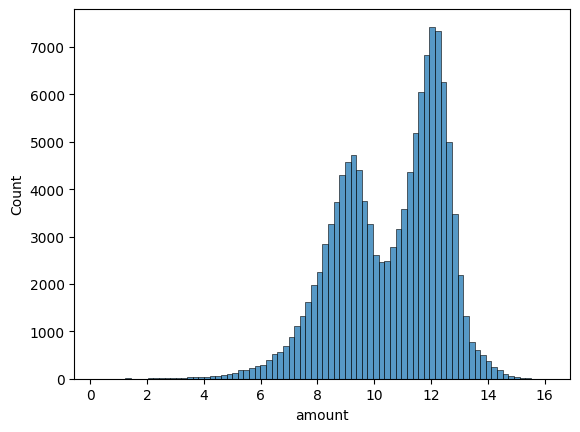

In [7]:
# sample EDA snippets
print(df['type'].value_counts())
df.groupby('type')['isFraud'].mean().sort_values(ascending=False)
sns.histplot(np.log1p(df['amount']), bins=80)

In [8]:
df['orig_delta'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['dest_delta'] = df['newbalanceDest'] - df['oldbalanceDest']
df['orig_match_amount'] = np.isclose(df['orig_delta'], df['amount'], atol=1e-2)

In [9]:
df['log_amount'] = np.log1p(df['amount'])
df['orig_is_merchant'] = df['nameOrig'].fillna('').str.startswith('M').astype(int)
df['dest_is_merchant'] = df['nameDest'].fillna('').str.startswith('M').astype(int)

gb = df.groupby('nameOrig')['amount']
df['orig_tx_count'] = gb.transform('count')
df['orig_avg_amount'] = gb.transform('mean')
df['amount_over_avg'] = df['amount']/ (df['orig_avg_amount'] + 1e-9)

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols.remove('isFraud') # Exclude the target variable

X = df[numeric_cols].fillna(0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)

/usr/local/lib/python3.11/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1784: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.uncentered_tss


In [11]:
df_cleaned = df.dropna(subset=['isFraud']).copy() # Create a copy to avoid SettingWithCopyWarning

# One-hot encode the 'type' column
df_cleaned = pd.get_dummies(df_cleaned, columns=['type'], drop_first=True)

# Define the list of features
# Include all numerical columns after one-hot encoding, excluding the target and potentially problematic columns
all_cols = df_cleaned.select_dtypes(include=np.number).columns.tolist()
features = [col for col in all_cols if col not in ['isFraud', 'isFlaggedFraud']] # Exclude target and flagged fraud

# Fill any remaining missing values in features with 0
df_cleaned[features] = df_cleaned[features].fillna(0)


X = df_cleaned[features]
y = df_cleaned['isFraud']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_val:", X_val.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_val:", y_val.shape)

Shape of X_train: (98704, 14)
Shape of X_val: (24677, 14)
Shape of y_train: (98704,)
Shape of y_val: (24677,)


In [13]:
import lightgbm as lgb

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_val, label=y_val)

params = {
  'objective': 'binary',
  'metric': ['auc','average_precision'],
  'boosting': 'gbdt',
  'learning_rate': 0.05,
  'num_leaves': 127,
  'max_depth': -1,
  'scale_pos_weight': (len(y_train)-y_train.sum())/ (y_train.sum()+1e-9),
  'feature_fraction': 0.8,
  'bagging_fraction': 0.8,
  'bagging_freq': 5,
  'verbosity': -1
}
model = lgb.train(params, train_data, valid_sets=[valid_data], num_boost_round=1000, callbacks=[lgb.early_stopping(stopping_rounds=50)])

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[48]	valid_0's auc: 0.928728	valid_0's average_precision: 0.580403


In [14]:
y_scores = model.predict(X_val)
avg_prec = average_precision_score(y_val, y_scores)
roc = roc_auc_score(y_val, y_scores)
print('PR-AUC', avg_prec, 'ROC-AUC', roc)

# choose threshold to maximize e.g., F1 or maximize recall while keeping precision > a minimum
from sklearn.metrics import precision_recall_curve
p, r, thresholds = precision_recall_curve(y_val, y_scores)
# plot precision-recall, choose threshold

PR-AUC 0.06131681072906477 ROC-AUC 0.9289406919561403


/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


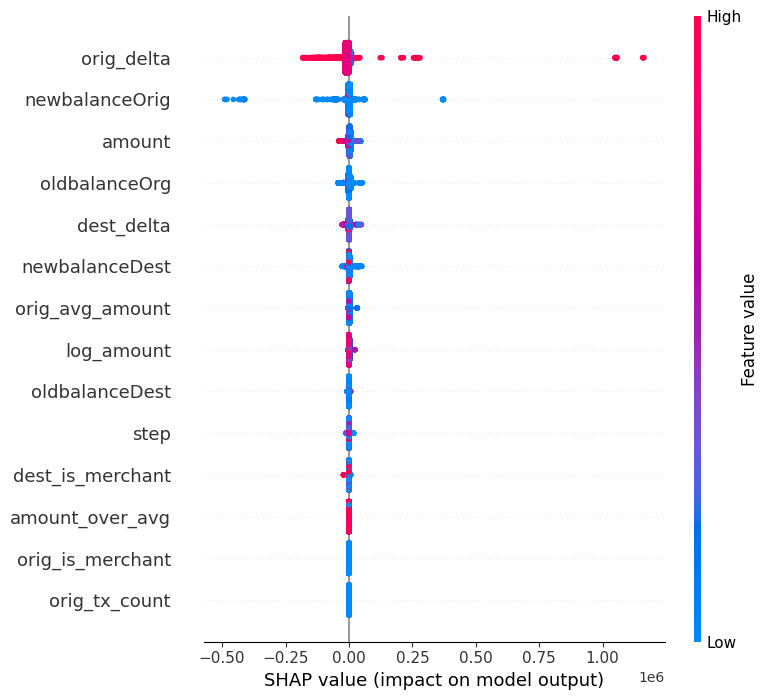

In [15]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)
shap.summary_plot(shap_values, X_val)